# cancelación de trabajos largos: Comparación con métodos publicados

**Nivel:** 3 **Requisitos previos:** Control secuencial y memoria nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se compara una nueva ejecución de la política aprendida con la referencia protegida medida en C07?

## Objetivos

Esta lección investiga la pregunta: ¿Cómo se compara una nueva ejecución de la política aprendida con la referencia protegida medida en C07?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M05-C07-nominal-40000; - `data/derived/episodes/M06-C07-nominal-40000; - `data/derived/episodes/M07-C07-nominal-40000; - `data/derived/episodes/M08-C07-nominal-40000; json`

## Método

Las redes recurrentes, la optimización de políticas con máscara y los modelos de transición aprendidos son enfoques establecidos de control secuencial. Su desempeño depende de la distribución de transiciones, recompensa, límites de episodio y máscara de acciones. La referencia XGBoost emparejada es un comparador aprendido no recurrente, no una afirmación externa de que los árboles sean el métodos publicados de toda tarea secuencial. Los cuarenta fallos C07 de M12 y el resultado de transferencia retenido de M04 explican por qué un puntaje agregado no basta. Las afirmaciones se limitan a las tareas registradas. La poscondición independiente debe inspeccionar el estado final y los efectos registrados, porque solicitar una cancelación no prueba que el trabajo se detuvo ni que un reintento no lo reinició. Las variantes emparejadas pueden probar cancelaciones antes del inicio, durante la ejecución y cerca del término, separando la respuesta del controlador del tiempo del entorno. Una red recurrente se justifica solo si su memoria cambia decisiones bajo observación parcial y mejora suficientes casos retenidos para compensar latencia y complejidad de estado. Una extensión útil desplaza el evento de cancelación a lo largo del trabajo sin cambiar su contenido, y mide finalización, tiempo y continuidad no deseada.

### cancelación de trabajos largos · nivel 3 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M05', 'M06', 'M04']
sample_case, seed = 'C07', 40000
evidence = load_lesson_evidence(
    ROOT, topic='03-sequential-control', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 3 | case variants: 18


### Comparar métodos entre variantes: control secuencial de cancelación

Las variantes de cancelación exponen el límite de fallo del controlador propuesto; informa cada semilla fallida y la latencia de decisión.

### cancelación de trabajos largos · nivel 3 | Ejecuta las políticas publicadas y compara la corrida

### cancelación de trabajos largos · nivel 3 | Compara la secuencia completa y no solo la primera acción

### cancelación de trabajos largos · nivel 3 | Recalcula resultados por variante desde todas las trazas del caso

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M04 boundary éxitos= 10 episodios= 10 tasa= 1.0
M04 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M04 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M04 nominal éxitos= 10 episodios= 10 tasa= 1.0
M04 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M04 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M05 boundary éxitos= 10 episodios= 10 tasa= 1.0
M05 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M05 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M05 nominal éxitos= 10 episodios= 10 tasa= 1.0
M05 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M05 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M06 boundary éxitos= 10 episodios= 10 tasa= 1.0
M06 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M06 duplicate_event éxitos= 0 episodios= 10 tasa= 0.0
M06 nominal éxitos= 10 episodios= 10 tasa= 1.0
M06 stale_conflict éxitos= 0 episodios= 10 tasa= 0.0
M06 unavailable_dependency éxitos= 0 episodios= 10 tasa= 0.0


### cancelación de trabajos largos · nivel 3 | Visualiza el estrés por variante sin mezclar familias

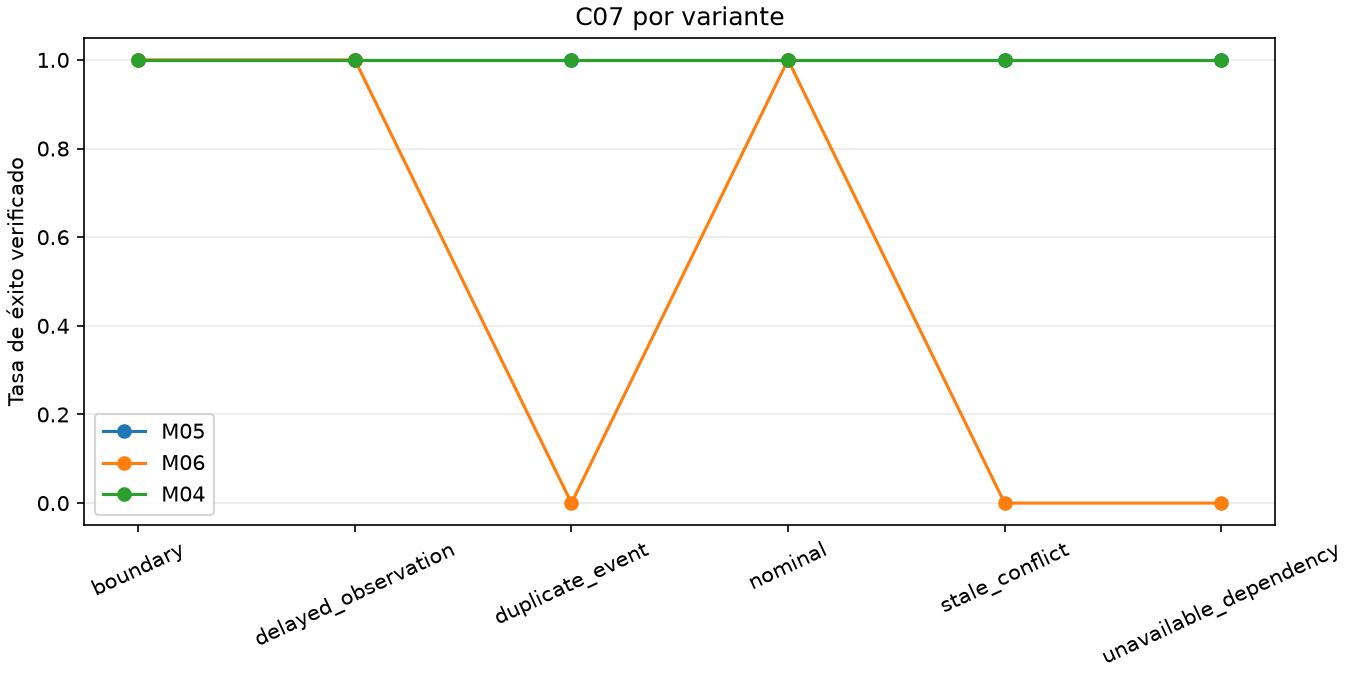

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### cancelación de trabajos largos · L3 | Construir la primera política ejecutable

Dentro de esta comparación de cancelación de trabajos largos (C07), construye M05 para cancelación de trabajos largos con la fábrica pública y conserva su contrato de observación antes de muestrear C07.

El gráfico 1, nivel 3, resume terminación verificada del trabajo después de cancelar para C07. El gráfico 1 ubica terminación verificada del trabajo después de cancelar en la familia diseñada C07 de nivel 3; Interpreta terminación verificada del trabajo después de cancelar en el gráfico 1 para C07 con su traza y poscondición antes de llamarlo mejora del control.

In [5]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M05'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M05


### cancelación de trabajos largos · L3 | Ejecutar el método principal en el caso indicado

En la comparación emparejada de cancelación de trabajos largos para C07, de cancelación de trabajos largos, el evaluador ejecuta M05 en C07 y deriva el éxito de la poscondición independiente, no de una traza reproducida.

In [6]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### cancelación de trabajos largos · L3 | Construir una política de comparación independiente

En la comparación emparejada de cancelación de trabajos largos para C07, crea M06 como objeto nuevo para impedir que el estado recurrente de M05 contamine la comparación.

In [7]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M06'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M06


### cancelación de trabajos largos · L3 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M06 en el mismo C07, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [8]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### cancelación de trabajos largos · L3 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de cancelación de trabajos largos, y las afirmaciones entre familias aún requieren el benchmark completo

In [9]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### cancelación de trabajos largos · L3 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de cancelación de trabajos largos recién ejecutados en C07, no se copia de un artefacto congelado

## Comparación
Las redes recurrentes, la optimización de políticas con máscara y los modelos de transición aprendidos son enfoques establecidos de control secuencial.

### cancelación de trabajos largos · L3 | Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para cancelación de trabajos largos ejecuta M04 en C07 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.

In [10]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


### cancelación de trabajos largos · L3 | Tiempo registrado del controlador

la figura de tiempos de cancelación de trabajos largos usa registros congelados y verificados por hash para M05 y M04 en C07, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para cancelación de trabajos largos describe el entorno registrado bajo su caso, variante y semilla declarados.

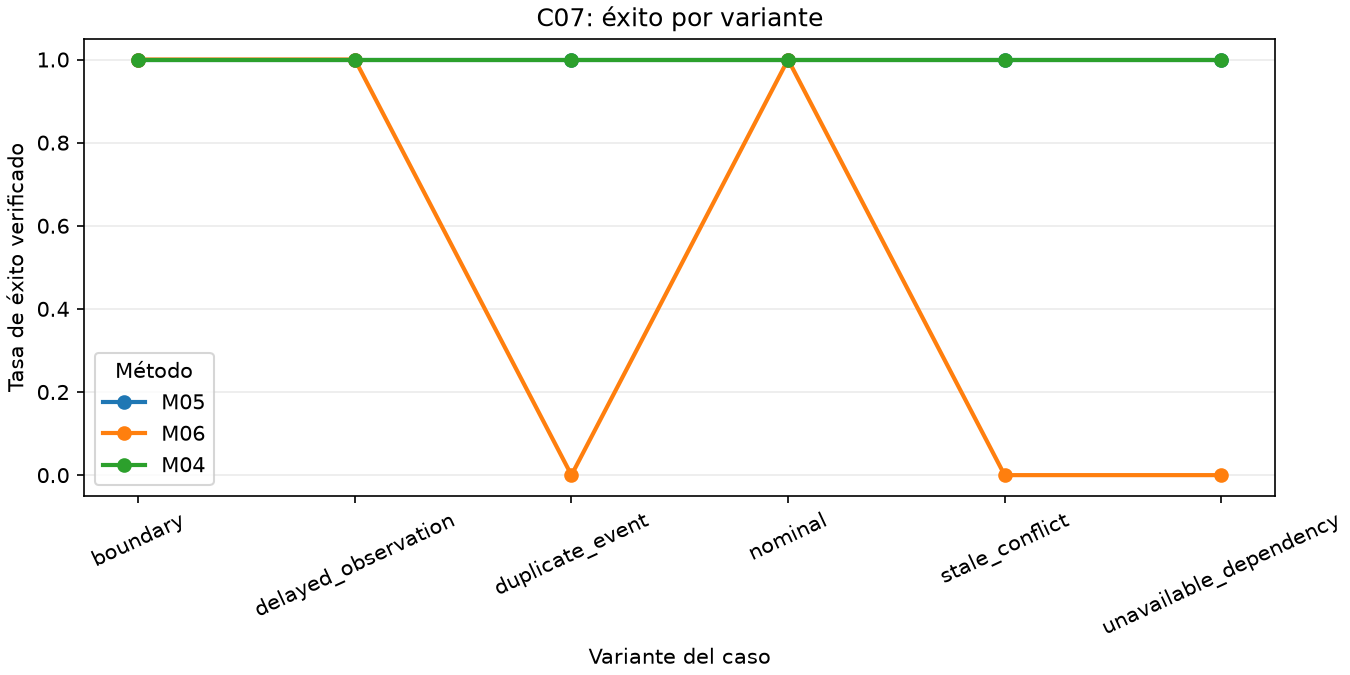

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para cancelación de trabajos largos, estas barras muestran resultados nuevos de poscondición de M05 y M06 en C07, Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En la comparación emparejada de cancelación de trabajos largos para C07, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

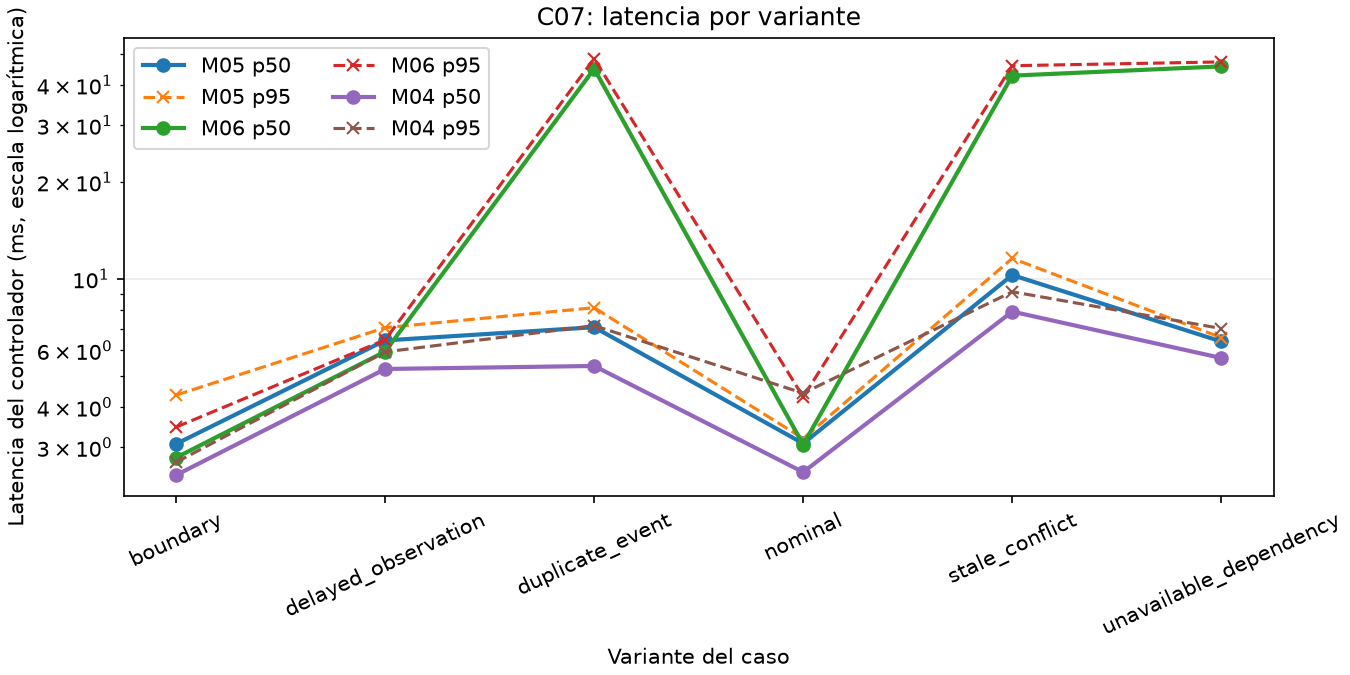

In [12]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Latencia del controlador (ms, escala logarítmica)")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": latencia por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para cancelación de trabajos largos lee registros canónicos de M05/M04 en C07, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. la solicitud no basta.

El gráfico 3, nivel 3, resume latencia del controlador separada de la duración asíncrona para C07.

## Resultados

**Respuesta:** La comparación de nivel 3 para cancelación de trabajos largos contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C07; esas 3 corridas emparejadas no establecen superioridad poblacional para cancelación de trabajos largos.

En la comparación emparejada de cancelación de trabajos largos para C07, los 40 fallos centrales de M12 están en C07, mientras varios métodos tienen éxito en los 200 episodios C07; El resultado identifica una brecha concreta; En la ejecución comparativa de cancelación de trabajos largos para C07, el éxito agregado no establece si la causó la recurrencia, la máscara de acciones, el error del modelo o el tiempo de cancelación;

En la comparación emparejada de cancelación de trabajos largos para C07, este paso de autoría no compromete salidas generadas;

lee ambos campos en la traza.

## Resumen

Informa el límite de fallo de C07 con sus variantes y semillas completas.




## Referencias
- [GRU](https://arxiv.org/abs/1406.1078) - [PPO](https://arxiv.org/abs/1707.06347) - [LINUCB](https://arxiv.org/abs/1003.0146)